In [ ]:
!pip -q install lightgbm optuna shap

In [ ]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

print("Данные загружены.")
print("Размер таблицы (строки, столбцы):", df.shape)
display(df.head())

Данные загружены.
Размер таблицы (строки, столбцы): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [ ]:
print("ИНФОРМАЦИЯ О ТАБЛИЦЕ")
df.info()

print("\nОПИСАТЕЛЬНАЯ СТАТИСТИКА")
display(df.describe(include="all").T)

print("\nКОЛИЧЕСТВО УНИКАЛЬНЫХ ЗНАЧЕНИЙ")
for column in df.select_dtypes(include="object").columns:
    print(f"{column}: {df[column].nunique()}")

ИНФОРМАЦИЯ О ТАБЛИЦЕ
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

ОПИСАТЕЛЬНАЯ СТАТИСТИКА


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292



КОЛИЧЕСТВО УНИКАЛЬНЫХ ЗНАЧЕНИЙ
Name: 891
Sex: 2
Ticket: 681
Cabin: 147
Embarked: 3


Полных дубликатов: 0
Дубликатов PassengerId: 0


,Количество пропусков,Процент пропусков
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


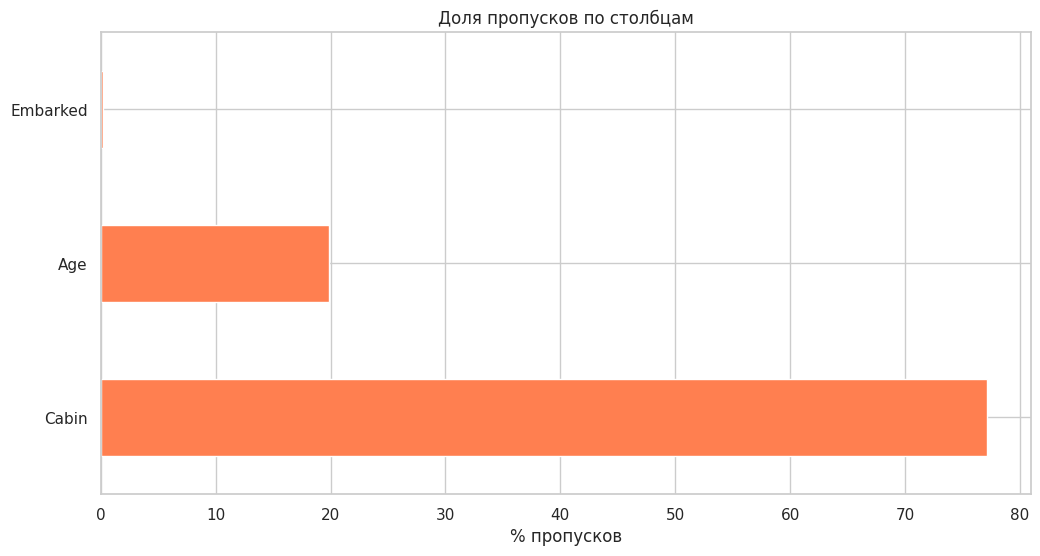

In [ ]:
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов PassengerId:", df["PassengerId"].duplicated().sum())

df = df.drop_duplicates().copy()

missing = pd.DataFrame({
    "Количество пропусков": df.isna().sum(),
    "Процент пропусков": (df.isna().mean() * 100).round(2)
})
missing = missing[missing["Количество пропусков"] > 0].sort_values(
    "Процент пропусков", ascending=False
)
display(missing)

if not missing.empty:
    missing["Процент пропусков"].plot(kind="barh", color="coral")
    plt.title("Доля пропусков по столбцам")
    plt.xlabel("% пропусков")
    plt.show()

Survived
0    549
1    342
Name: count, dtype: int64

Доли классов:


,Доля
Survived,
0,0.616162
1,0.383838


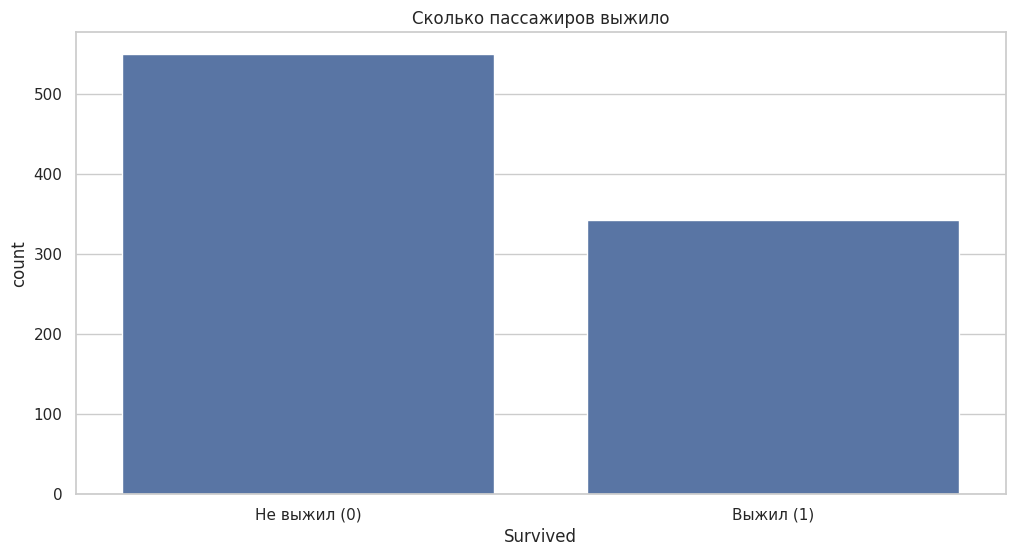

Доля выживших по полу:


,Survived
Sex,
female,0.742038
male,0.188908


Доля выживших по классу билета:


,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


In [ ]:
print(df["Survived"].value_counts())
print("\nДоли классов:")
display(df["Survived"].value_counts(normalize=True).rename("Доля"))

sns.countplot(data=df, x="Survived")
plt.title("Сколько пассажиров выжило")
plt.xticks([0, 1], ["Не выжил (0)", "Выжил (1)"])
plt.show()

survival_by_sex = df.groupby("Sex")["Survived"].mean()
survival_by_class = df.groupby("Pclass")["Survived"].mean()
print("Доля выживших по полу:")
display(survival_by_sex)
print("Доля выживших по классу билета:")
display(survival_by_class)

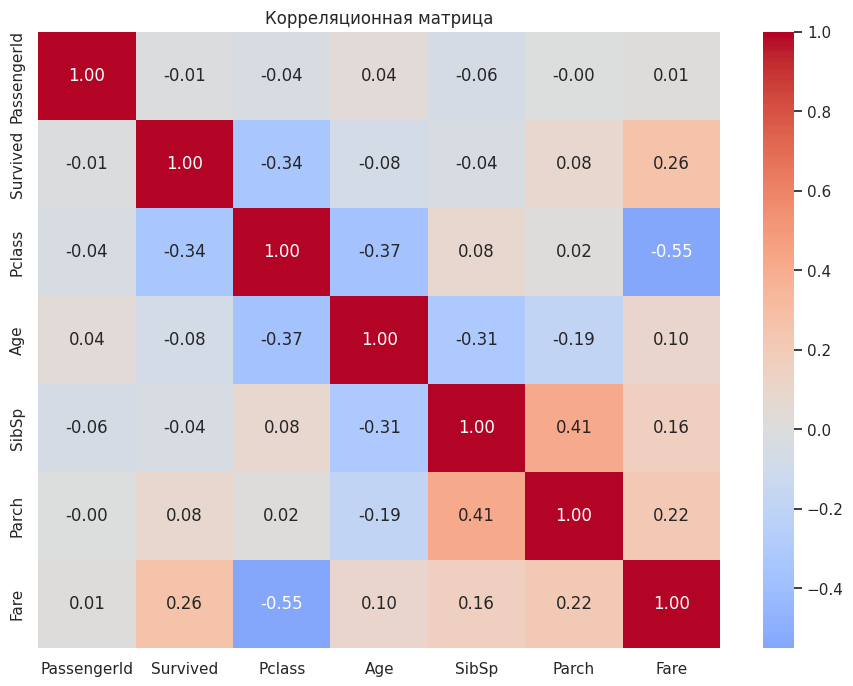

In [ ]:
numeric_df = df.select_dtypes(include=np.number)
corr = numeric_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Корреляционная матрица")
plt.show()

In [ ]:
X_raw = df.drop(columns=["Survived"])
y = df["Survived"].astype(int)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train_raw.shape, "Test:", X_test_raw.shape)
print("Доли классов в train:")
display(y_train.value_counts(normalize=True))

Train: (712, 11) Test: (179, 11)
Доли классов в train:


,proportion
Survived,
0,0.616573
1,0.383427


In [ ]:
class TitanicPreprocessor:
    """Подготавливает признаки Titanic без обучения на тестовых данных."""

    def __init__(self):
        self.age_medians = None
        self.global_age_median = None
        self.embarked_mode = None
        self.fare_median = None
        self.columns_after_encoding = None

    @staticmethod
    def add_features(data: pd.DataFrame) -> pd.DataFrame:
        data = data.copy()

        # Извлекаем обращение/титул из имени: Mr, Mrs, Miss, Master и т.д.
        data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
        data["Title"] = data["Title"].replace({
            "Lady": "Rare", "Countess": "Rare", "Capt": "Rare", "Col": "Rare",
            "Don": "Rare", "Dr": "Rare", "Major": "Rare", "Rev": "Rare",
            "Sir": "Rare", "Jonkheer": "Rare", "Dona": "Rare"
        })
        data["Title"] = data["Title"].replace({
            "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"
        })

        data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
        data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
        data["ClassSex"] = data["Pclass"].astype(str) + "_" + data["Sex"].astype(str)

        # Убираем столбцы, которые напрямую не используем в модели.
        data = data.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"], errors="ignore")
        return data

    def fit(self, data: pd.DataFrame):
        prepared = self.add_features(data)
        self.age_medians = prepared.groupby(["Title", "Pclass"])["Age"].median()
        self.global_age_median = prepared["Age"].median()
        self.embarked_mode = prepared["Embarked"].mode().iloc[0]
        self.fare_median = prepared["Fare"].median()
        return self

    def transform(self, data: pd.DataFrame) -> pd.DataFrame:
        prepared = self.add_features(data)

        def fill_age(row):
            if pd.notna(row["Age"]):
                return row["Age"]
            key = (row["Title"], row["Pclass"])
            return self.age_medians.get(key, self.global_age_median)

        prepared["Age"] = prepared.apply(fill_age, axis=1)
        prepared["IsChild"] = (prepared["Age"] < 15).astype(int)
        prepared["Embarked"] = prepared["Embarked"].fillna(self.embarked_mode)
        prepared["Fare"] = prepared["Fare"].fillna(self.fare_median)

        prepared["FamilySizeBin"] = pd.cut(
            prepared["FamilySize"], bins=[0, 1, 3, 5, 20],
            labels=["Alone", "Small", "Medium", "Large"], include_lowest=True
        )
        prepared["AgeBin"] = pd.cut(
            prepared["Age"], bins=[0, 12, 20, 40, 60, 100],
            labels=["Child", "Teen", "Adult", "Middle", "Senior"],
            include_lowest=True
        )
        prepared["FareBin"] = pd.cut(
            prepared["Fare"],
            bins=[-0.01, 7.91, 14.454, 31.0, np.inf],
            labels=["Q1", "Q2", "Q3", "Q4"]
        )
        prepared["AgeFare"] = prepared["Age"] * prepared["Fare"]

        categorical = [
            "Sex", "Embarked", "Title", "AgeBin", "FareBin",
            "FamilySizeBin", "ClassSex"
        ]
        prepared = pd.get_dummies(prepared, columns=categorical, dtype=int)

        if self.columns_after_encoding is not None:
            prepared = prepared.reindex(columns=self.columns_after_encoding, fill_value=0)
        return prepared

    def fit_transform(self, data: pd.DataFrame) -> pd.DataFrame:
        self.fit(data)
        transformed = self.transform(data)
        self.columns_after_encoding = transformed.columns.tolist()
        return transformed


preprocessor = TitanicPreprocessor()
X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

print("После подготовки:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Пропусков train:", X_train.isna().sum().sum())
display(X_train.head())

После подготовки:
X_train: (712, 38)
X_test: (179, 38)
Пропусков train: 0


,Pclass,Age,SibSp,Parch,Fare,FamilySize,IsAlone,IsChild,AgeFare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S,Title_Master,Title_Miss,Title_Mr,Title_Mrs,Title_Rare,AgeBin_Child,AgeBin_Teen,AgeBin_Adult,AgeBin_Middle,AgeBin_Senior,FareBin_Q1,FareBin_Q2,FareBin_Q3,FareBin_Q4,FamilySizeBin_Alone,FamilySizeBin_Small,FamilySizeBin_Medium,FamilySizeBin_Large,ClassSex_1_female,ClassSex_1_male,ClassSex_2_female,ClassSex_2_male,ClassSex_3_female,ClassSex_3_male
692,3,27.0,0,0,56.4958,1,1,0,1525.3866,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,1
481,2,30.0,0,0,0.0000,1,1,0,0.0000,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0,0
527,1,40.0,0,0,221.7792,1,1,0,8871.1680,0,1,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,1,0,0,0,0
855,3,18.0,0,1,9.3500,2,0,0,168.3000,1,0,0,0,1,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,1,0,0,0,0,0,0,1,0
801,2,31.0,1,1,26.2500,3,0,0,813.7500,1,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0


In [ ]:
print("Примеры столбцов после кодирования:")
print([c for c in X_train.columns if c.startswith(("Sex_", "Embarked_", "Title_"))][:20])

Примеры столбцов после кодирования:
['Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare']


In [ ]:
def make_lgb_params(extra_params: Optional[Dict[str, Any]] = None) -> Dict[str, Any]:
    params = {
        "objective": "binary",
        "metric": "auc",
        "learning_rate": 0.03,
        "num_leaves": 15,
        "max_depth": -1,
        "feature_fraction": 0.9,
        "bagging_fraction": 0.9,
        "bagging_freq": 1,
        "min_data_in_leaf": 15,
        "lambda_l1": 0.0,
        "lambda_l2": 1.0,
        "verbosity": -1,
        "seed": RANDOM_STATE,
        "feature_fraction_seed": RANDOM_STATE,
        "bagging_seed": RANDOM_STATE
    }
    if extra_params:
        params.update(extra_params)
    return params


def cross_validate_lgb(
    X: pd.DataFrame,
    y: pd.Series,
    params: Dict[str, Any],
    n_splits: int = 5,
    num_boost_round: int = 700,
    show_progress: bool = True
) -> Tuple[List[lgb.Booster], List[float], List[dict]]:
    """Обучает одну LightGBM-модель на каждом фолде и возвращает модели и AUC."""
    splitter = StratifiedKFold(
        n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE
    )
    models, scores, histories = [], [], []

    for fold, (train_idx, valid_idx) in enumerate(splitter.split(X, y), start=1):
        X_fold_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
        y_fold_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

        train_set = lgb.Dataset(X_fold_train, label=y_fold_train)
        valid_set = lgb.Dataset(X_valid, label=y_valid, reference=train_set)

        model = lgb.train(
            params,
            train_set,
            num_boost_round=num_boost_round,
            valid_sets=[valid_set],
            valid_names=["valid"],
            callbacks=[
                lgb.early_stopping(stopping_rounds=60, verbose=False),
                lgb.log_evaluation(period=0)
            ]
        )

        probabilities = model.predict(X_valid, num_iteration=model.best_iteration)
        score = roc_auc_score(y_valid, probabilities)
        models.append(model)
        scores.append(score)
        histories.append({
            "fold": fold,
            "auc": score,
            "best_iteration": model.best_iteration
        })
        if show_progress:
            print(f"Фолд {fold}: AUC = {score:.4f}, лучшая итерация = {model.best_iteration}")

    if show_progress:
        print(f"Средний AUC: {np.mean(scores):.4f} ± {np.std(scores):.4f}")
    return models, scores, histories


base_params = make_lgb_params()
base_models, cv_scores, cv_history = cross_validate_lgb(
    X_train, y_train, base_params
)

Фолд 1: AUC = 0.8738, лучшая итерация = 17
Фолд 2: AUC = 0.8631, лучшая итерация = 183
Фолд 3: AUC = 0.9118, лучшая итерация = 10
Фолд 4: AUC = 0.8900, лучшая итерация = 4
Фолд 5: AUC = 0.8702, лучшая итерация = 9
Средний AUC: 0.8818 ± 0.0174


In [ ]:
RUN_OPTUNA = True
N_TRIALS = 25  # Можно увеличить, например, до 50 или 100.


def objective(trial):
    trial_params = {
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.12, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 7, 40),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "feature_fraction": trial.suggest_float("feature_fraction", 0.65, 1.0),
        "bagging_fraction": trial.suggest_float("bagging_fraction", 0.65, 1.0),
        "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 8, 40),
        "lambda_l1": trial.suggest_float("lambda_l1", 1e-4, 5.0, log=True),
        "lambda_l2": trial.suggest_float("lambda_l2", 1e-4, 5.0, log=True)
    }
    params = make_lgb_params(trial_params)
    _, scores, _ = cross_validate_lgb(
        X_train, y_train, params, n_splits=5, num_boost_round=500,
        show_progress=False
    )
    return float(np.mean(scores))


if RUN_OPTUNA:
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(direction="maximize")
    study.optimize(objective, n_trials=N_TRIALS)
    best_params = make_lgb_params(study.best_params)
    print("Лучший AUC на CV:", round(study.best_value, 4))
    print("Лучшие параметры:")
    print(study.best_params)
else:
    best_params = base_params
    print("Optuna пропущена; используем базовые параметры.")

Лучший AUC на CV: 0.8973
Лучшие параметры:
{'learning_rate': 0.11568805127830357, 'num_leaves': 9, 'max_depth': 8, 'feature_fraction': 0.8361151698185932, 'bagging_fraction': 0.7687503067875354, 'min_data_in_leaf': 37, 'lambda_l1': 0.004157966163255325, 'lambda_l2': 0.4762087540372741}


In [ ]:
final_models, final_cv_scores, final_cv_history = cross_validate_lgb(
    X_train, y_train, best_params, n_splits=5, num_boost_round=900
)

Фолд 1: AUC = 0.8897, лучшая итерация = 71
Фолд 2: AUC = 0.8708, лучшая итерация = 69
Фолд 3: AUC = 0.9302, лучшая итерация = 51
Фолд 4: AUC = 0.9065, лучшая итерация = 118
Фолд 5: AUC = 0.8895, лучшая итерация = 49
Средний AUC: 0.8973 ± 0.0199


In [ ]:
def predict_ensemble(models: List[lgb.Booster], X: pd.DataFrame) -> np.ndarray:
    predictions = [
        model.predict(X, num_iteration=model.best_iteration) for model in models
    ]
    return np.mean(predictions, axis=0)


def evaluate_model(
    models: List[lgb.Booster],
    X_test: pd.DataFrame,
    y_test: pd.Series,
    threshold: float = 0.5
) -> Dict[str, Any]:
    probabilities = predict_ensemble(models, X_test)
    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(y_test, predictions, labels=[0, 1]).ravel()

    return {
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(y_test, predictions, zero_division=0),
        "recall": recall_score(y_test, predictions, zero_division=0),
        "f1": f1_score(y_test, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_test, probabilities),
        "tn": tn, "fp": fp, "fn": fn, "tp": tp,
        "probabilities": probabilities,
        "predictions": predictions
    }


test_metrics = evaluate_model(final_models, X_test, y_test)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"{metric:>10}: {test_metrics[metric]:.4f}")

print("\nМатрица ошибок:")
print(confusion_matrix(y_test, test_metrics["predictions"], labels=[0, 1]))

  accuracy: 0.8045
 precision: 0.7833
    recall: 0.6812
        f1: 0.7287
   roc_auc: 0.8597

Матрица ошибок:
[[97 13]
 [22 47]]


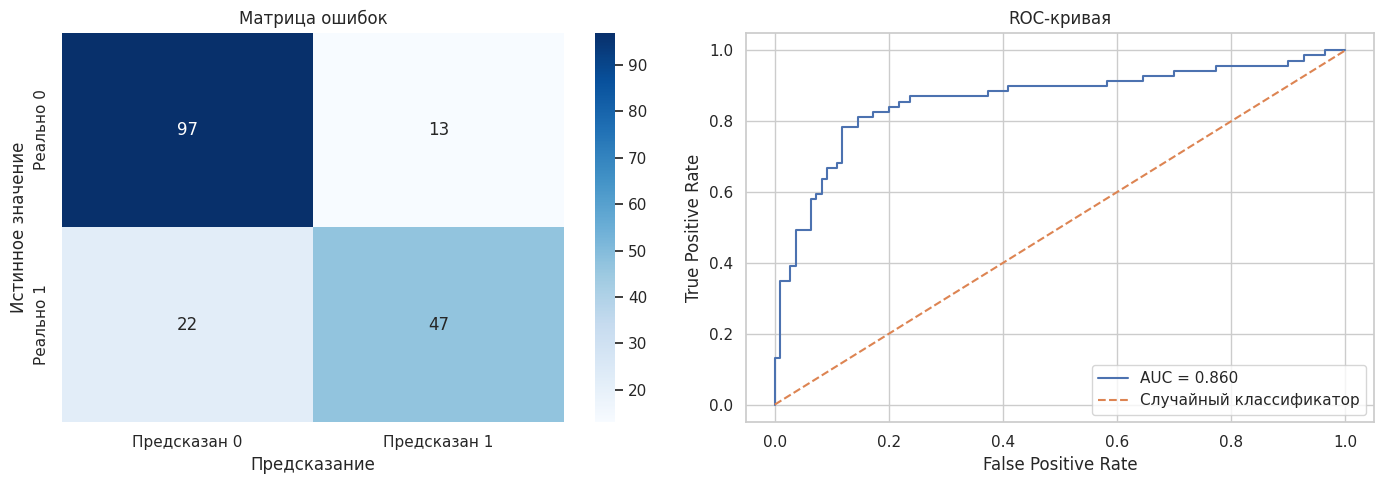

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm = confusion_matrix(y_test, test_metrics["predictions"], labels=[0, 1])
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=["Предсказан 0", "Предсказан 1"],
    yticklabels=["Реально 0", "Реально 1"]
)
axes[0].set_title("Матрица ошибок")
axes[0].set_xlabel("Предсказание")
axes[0].set_ylabel("Истинное значение")

fpr, tpr, _ = roc_curve(y_test, test_metrics["probabilities"])
axes[1].plot(fpr, tpr, label=f"AUC = {test_metrics['roc_auc']:.3f}")
axes[1].plot([0, 1], [0, 1], linestyle="--", label="Случайный классификатор")
axes[1].set_title("ROC-кривая")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.show()

,Признак,Важность
16,Title_Mr,439.075023
8,AgeFare,245.847537
4,Fare,244.475189
9,Sex_female,236.226257
0,Pclass,204.531973
1,Age,163.575647
10,Sex_male,72.384976
5,FamilySize,63.100476
13,Embarked_S,37.437368
35,ClassSex_2_male,19.291986


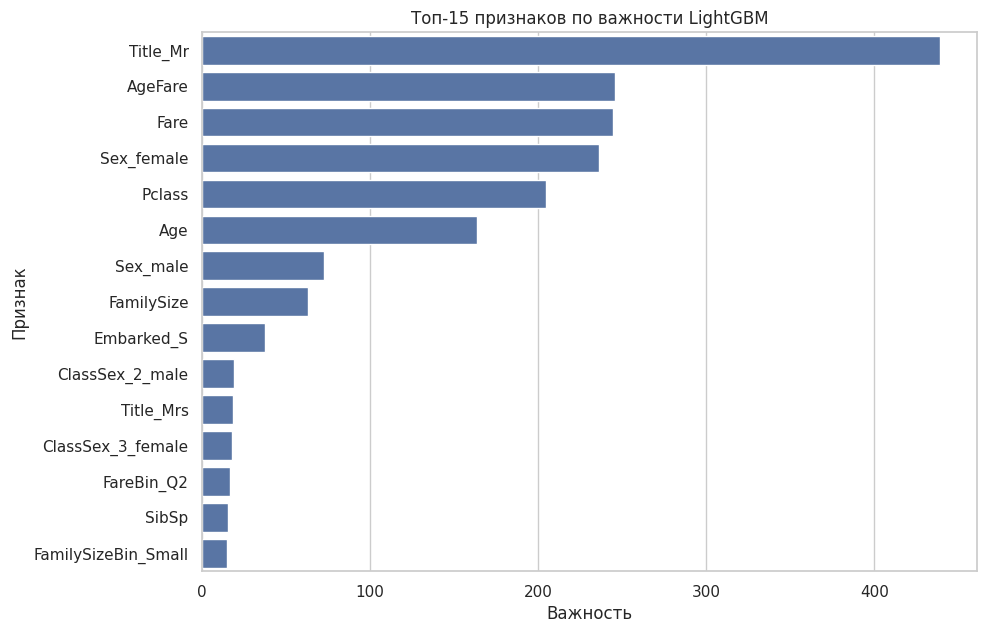

In [ ]:
importance = np.mean(
    [model.feature_importance(importance_type="gain") for model in final_models],
    axis=0
)
importance_df = pd.DataFrame({
    "Признак": X_train.columns,
    "Важность": importance
}).sort_values("Важность", ascending=False)

display(importance_df.head(15))

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df.head(15), x="Важность", y="Признак")
plt.title("Топ-15 признаков по важности LightGBM")
plt.show()

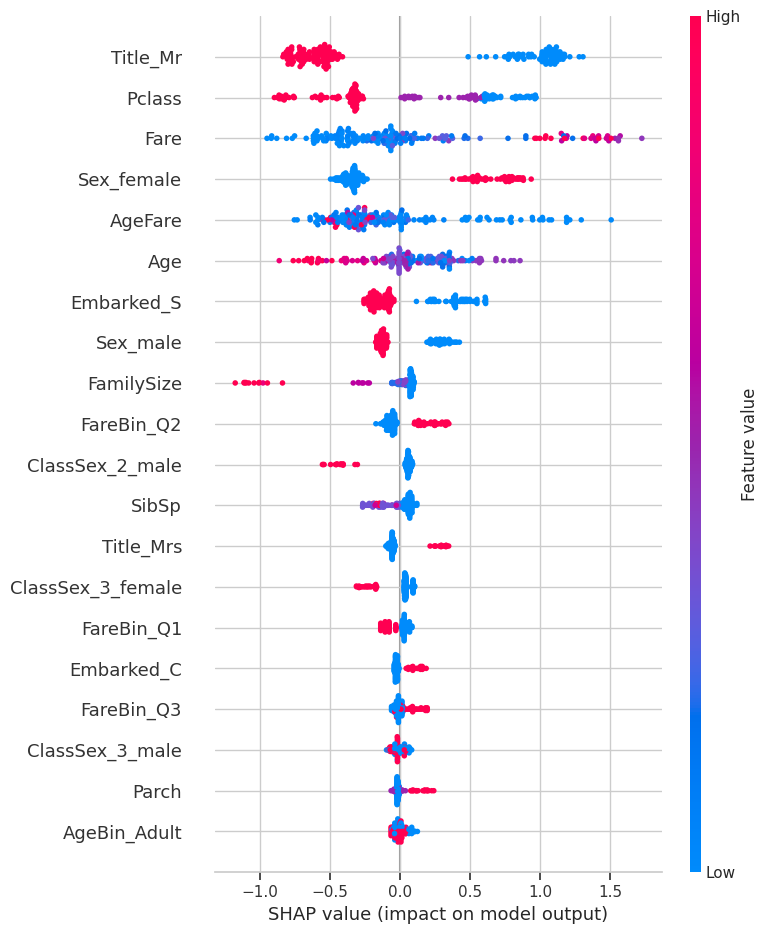

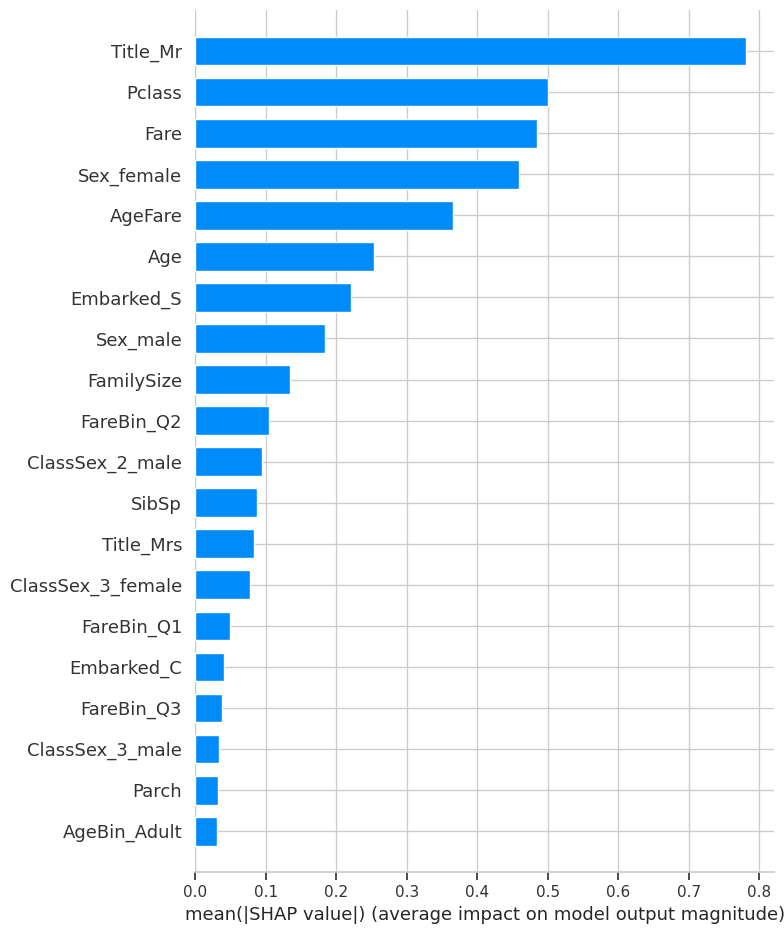

In [ ]:
try:
    explainer = shap.TreeExplainer(final_models[0])
    shap_values = explainer(X_test)

    # В разных версиях SHAP формат результата может отличаться.
    values = shap_values.values
    if values.ndim == 3:
        values = values[:, :, 1]

    shap.summary_plot(values, X_test, show=True)
    shap.summary_plot(values, X_test, plot_type="bar", show=True)
except Exception as error:
    print("SHAP-график не построился в этой версии библиотеки:", error)

In [ ]:
importance_df["Доля важности"] = (
    importance_df["Важность"] / max(importance_df["Важность"].sum(), 1e-12)
)
weak_features = importance_df.loc[
    importance_df["Доля важности"] < 0.001, "Признак"
].tolist()

print("Признаков с долей важности меньше 0.1%:", len(weak_features))
print(weak_features[:30])

Признаков с долей важности меньше 0.1%: 13
['Title_Miss', 'ClassSex_2_female', 'AgeBin_Middle', 'FareBin_Q4', 'IsChild', 'Title_Rare', 'AgeBin_Child', 'Title_Master', 'Embarked_Q', 'FamilySizeBin_Alone', 'AgeBin_Senior', 'FamilySizeBin_Medium', 'FamilySizeBin_Large']


In [ ]:
tn, fp, fn, tp = (
    test_metrics["tn"], test_metrics["fp"],
    test_metrics["fn"], test_metrics["tp"]
)
business_score = tp * 10 - fn * 15 - fp * 5

print(f"TP={tp}, FN={fn}, FP={fp}, TN={tn}")
print(f"Условный бизнес-балл: {business_score}")

TP=47, FN=22, FP=13, TN=97
Условный бизнес-балл: 75


In [ ]:
print("=" * 60)
print("TITANIC ML PROJECT — ИТОГОВЫЙ ОТЧЁТ")
print("=" * 60)
print(f"Исходных пассажиров: {len(df)}")
print(f"Признаков после подготовки: {X_train.shape[1]}")
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"CV AUC: {np.mean(final_cv_scores):.4f} ± {np.std(final_cv_scores):.4f}")
print(f"Test Accuracy: {test_metrics['accuracy']:.4f}")
print(f"Test Precision: {test_metrics['precision']:.4f}")
print(f"Test Recall: {test_metrics['recall']:.4f}")
print(f"Test F1: {test_metrics['f1']:.4f}")
print(f"Test ROC AUC: {test_metrics['roc_auc']:.4f}")
print(f"Условный бизнес-балл: {business_score}")
print("\nТоп-5 признаков:")
display(importance_df.head(5))
print("Проект завершён.")

TITANIC ML PROJECT — ИТОГОВЫЙ ОТЧЁТ
Исходных пассажиров: 891
Признаков после подготовки: 38
Train: 712 | Test: 179
CV AUC: 0.8973 ± 0.0199
Test Accuracy: 0.8045
Test Precision: 0.7833
Test Recall: 0.6812
Test F1: 0.7287
Test ROC AUC: 0.8597
Условный бизнес-балл: 75

Топ-5 признаков:


,Признак,Важность,Доля важности
16,Title_Mr,439.075023,0.233778
8,AgeFare,245.847537,0.130898
4,Fare,244.475189,0.130167
9,Sex_female,236.226257,0.125775
0,Pclass,204.531973,0.108900


Проект завершён.
